In [1]:
import torch
import numpy
import torch.nn as nn
import torch.nn.functional as f

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [3]:
df = pd.read_csv("/dl/data/user_visit_duration.csv")

In [4]:
df.head()

,Time (min),Buy
0,2.000000,0
1,0.683333,0
2,3.216667,1
3,0.900000,0
4,1.533333,1


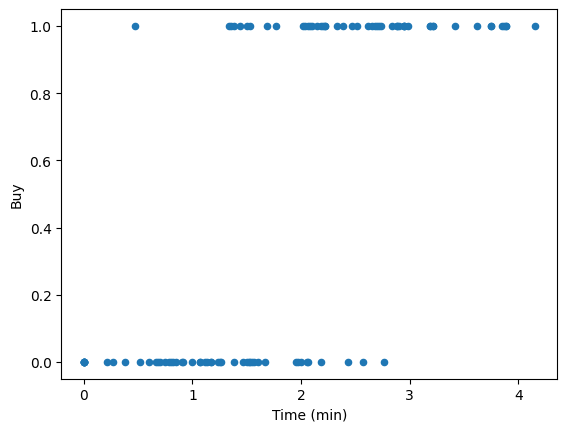

In [5]:
df.plot(kind='scatter',
       x='Time (min)',
       y='Buy');

In [6]:
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import SGD

In [7]:
model = Sequential()
model.add(Dense(1, input_shape=(1, ), activation='sigmoid'))

In [8]:
model.compile(SGD(learning_rate=0.5), 'binary_crossentropy', metrics=['accuracy'])

In [9]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 1)                 2         
                                                                 
Total params: 2 (8.00 Byte)
Trainable params: 2 (8.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [10]:
X = df[["Time (min)"]].values
y = df[["Buy"]].values

In [11]:
model.fit(X, y, epochs=25)

Epoch 1/25


4/4 [==============================] - 1s 8ms/step - loss: 0.7483 - accuracy: 0.5900
Epoch 2/25
4/4 [==============================] - 0s 7ms/step - loss: 0.5515 - accuracy: 0.7100
Epoch 3/25
4/4 [==============================] - 0s 6ms/step - loss: 0.5356 - accuracy: 0.7100
Epoch 4/25
4/4 [==============================] - 0s 6ms/step - loss: 0.5157 - accuracy: 0.7500
Epoch 5/25
4/4 [==============================] - 0s 5ms/step - loss: 0.4993 - accuracy: 0.8300
Epoch 6/25
4/4 [==============================] - 0s 6ms/step - loss: 0.4938 - accuracy: 0.7700
Epoch 7/25
4/4 [==============================] - 0s 6ms/step - loss: 0.4774 - accuracy: 0.8000
Epoch 8/25
4/4 [==============================] - 0s 6ms/step - loss: 0.4644 - accuracy: 0.8100
Epoch 9/25
4/4 [==============================] - 0s 5ms/step - loss: 0.4658 - accuracy: 0.7900
Epoch 10/25
4/4 [==============================] - 0s 6ms/step - loss: 0.4575 - accuracy: 0.8200
Epoch 11/25
4/4 [====================

2/2 [==============================] - 0s 9ms/step


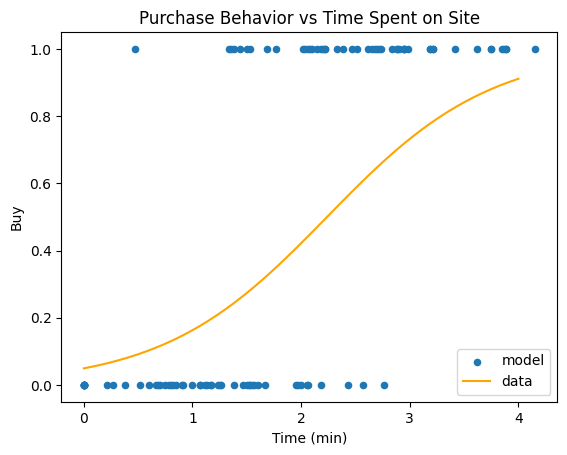

In [12]:
ax = df.plot(kind='scatter',
             x='Time (min)',
             y='Buy',
             title='Purchase Behavior vs Time Spent on Site');
temp = np.linspace(0, 4)
ax.plot(temp, model.predict(temp), color='orange')
plt.legend(['model', 'data'])

In [13]:
temp_class = model.predict(temp) > 0.5
type(temp_class)

2/2 [==============================] - 0s 6ms/step


numpy.ndarray

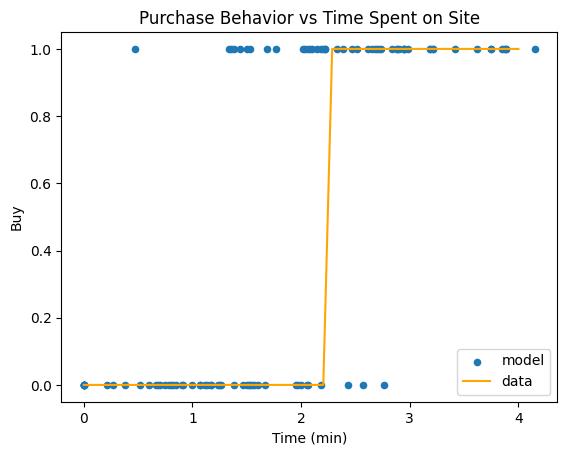

In [14]:
ax = df.plot(kind='scatter',
             x='Time (min)',
             y='Buy',
             title='Purchase Behavior vs Time Spent on Site');
temp = np.linspace(0, 4)
ax.plot(temp, temp_class, color='orange')
plt.legend(['model', 'data'])

In [15]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

In [16]:
y_pred = model.predict(X)
y_class_pred = y_pred > 0.5

4/4 [==============================] - 0s 5ms/step


In [17]:
print(f"Accuracy score is {accuracy_score(y, y_class_pred):0.3f}")

Accuracy score is 0.780


In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

In [19]:
# Reset the model parameters
params = model.get_weights()
params = [np.zeros(w.shape) for w in params]
model.set_weights(params)

In [20]:
# Model performance will be bad after reset parameters
print(f"Accuracy score is {accuracy_score(y, model.predict(X) > 0.5):0.3f}")

4/4 [==============================] - 0s 5ms/step
Accuracy score is 0.500


In [21]:
model.fit(X_train, y_train, epochs=25, verbose=0)

In [22]:
print("The train accuracy score is {:0.3f}".format(accuracy_score(y_train, model.predict(X_train) > 0.5)))
print(f"The test accuracy score is {accuracy_score(y_test, model.predict(X_test) > 0.5):0.3f}")

3/3 [==============================] - 0s 6ms/step
The train accuracy score is 0.838
1/1 [==============================] - 0s 73ms/step
The test accuracy score is 0.800


In [23]:
# !pip install scikeras
from scikeras.wrappers import KerasClassifier
from sklearn.model_selection import cross_val_score, KFold

In [24]:
def build_logistic_regression_model():
    model = Sequential()
    model.add(Dense(1, input_shape=(1, ), activation='sigmoid'))
    model.compile(SGD(learning_rate=0.5),
                 'binary_crossentropy',
                 metrics=['accuracy'])
    return model

In [25]:
model = KerasClassifier(model=build_logistic_regression_model, epochs=25, random_state=42)

In [26]:
cv = KFold(3, shuffle=True)
scores = cross_val_score(model, X, y, cv=cv)

Epoch 1/25
3/3 [==============================] - 1s 11ms/step - loss: 0.8132 - accuracy: 0.5455
Epoch 2/25
3/3 [==============================] - 0s 8ms/step - loss: 0.8261 - accuracy: 0.5606
Epoch 3/25
3/3 [==============================] - 0s 9ms/step - loss: 0.6308 - accuracy: 0.5606
Epoch 4/25
3/3 [==============================] - 0s 8ms/step - loss: 0.5743 - accuracy: 0.7879
Epoch 5/25
3/3 [==============================] - 0s 8ms/step - loss: 0.6034 - accuracy: 0.6364
Epoch 6/25
3/3 [==============================] - 0s 9ms/step - loss: 0.5717 - accuracy: 0.7121
Epoch 7/25
3/3 [==============================] - 0s 8ms/step - loss: 0.5858 - accuracy: 0.6515
Epoch 8/25
3/3 [==============================] - 0s 9ms/step - loss: 0.5230 - accuracy: 0.7273
Epoch 9/25
3/3 [==============================] - 0s 9ms/step - loss: 0.5361 - accuracy: 0.7727
Epoch 10/25
3/3 [==============================] - 0s 8ms/step - loss: 0.5126 - accuracy: 0.8182
Epoch 11/25
3/3 [=====================

In [27]:
scores, type(scores)

(array([0.88235294, 0.75757576, 0.75757576]), numpy.ndarray)

In [28]:
print(f"The cross validation accuracy is {scores.mean():0.4f} ± {scores.std():0.4f}")

The cross validation accuracy is 0.7992 ± 0.0588


In [29]:
from sklearn.metrics import confusion_matrix

In [30]:
confusion_matrix(y, y_class_pred)
# TN FP
# FN TP

array([[47,  3],
       [19, 31]], dtype=int64)

In [31]:
def pretty_confusion_matrix(y_true, y_pred, labels=["False", "True"]):
    cm = confusion_matrix(y_true, y_pred)
    pred_labels = ['Predicted '+ l for l in labels]
    df = pd.DataFrame(cm, index=labels, columns=pred_labels)
    return df

In [32]:
pretty_confusion_matrix(y, y_class_pred, ['Not Buy', 'Buy'])

,Predicted Not Buy,Predicted Buy
Not Buy,47,3
Buy,19,31


In [33]:
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

In [34]:
print(f"Precision:\t{precision_score(y, y_class_pred):0.3f}")
print(f"Recall:  \t{recall_score(y, y_class_pred):0.3f}")
print(f"F1 Score:\t{f1_score(y, y_class_pred):0.3f}")

Precision:	0.912
Recall:  	0.620
F1 Score:	0.738


In [35]:
print(classification_report(y, y_class_pred))

              precision    recall  f1-score   support

           0       0.71      0.94      0.81        50
           1       0.91      0.62      0.74        50

    accuracy                           0.78       100
   macro avg       0.81      0.78      0.77       100
weighted avg       0.81      0.78      0.77       100

